In [33]:
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

REPO_ROOT = Path.cwd().parent      # the folder that contains the platform package `app`
CODE_DIR = Path.cwd()              # the folder with strategy_gp.py, lab.py, platform_bridge.py, ...
for path in (REPO_ROOT, CODE_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from app.strategies.genetic.experiment import arm0_random
import app.strategies.genetic.experiment.arm5_demo_gp_optuna as arm5
import app.strategies.genetic.llm.lab as lab
import app.strategies.genetic.platform_bridge as pb
from app.strategies.genetic.rule_strategy import RuleStrategy
from app.data.data_provider import GapsFoundError, OHLCVDataProvider

pd.set_option("display.max_colwidth", 140)

In [34]:
SYMBOL, EXCHANGE, TIMEFRAME = "BTC/USDT", "binance", "1h"
START = datetime(2022, 1, 1, tzinfo=timezone.utc)
END = datetime(2026, 10, 1, tzinfo=timezone.utc)
HOLDOUT_FRACTION = 0.25  # the last quarter of the bars: never seen by the search
BUDGET = 2000  # backtests per arm and seed (B), the same for both arms
K = 10  # Optuna trials per GP structure
POP = 30  # GP population
SEEDS = [0]  # one seed for a demo; at least five for the experiment
PLATFORM_SEEDS = SEEDS[:1]  # rules handed in under these seeds are re-run on the platform engine
MONEY = 10_000.0
COST_BPS = 12  # fee + slippage per side in the fast engine

lab.BARS_PER_YEAR = pb.BARS_PER_YEAR[TIMEFRAME]
lab.COST_BPS = COST_BPS
STRATEGY = dict(symbol=SYMBOL, exchange=EXCHANGE, timeframe=TIMEFRAME)


def make_provider(strategy, start=START, end=END):
    """A fresh candle provider, built the way the backtest Celery task builds it."""
    return OHLCVDataProvider(strategy, start, end, EXCHANGE, SYMBOL, TIMEFRAME)

In [37]:
 ## 1. Candles
probe = RuleStrategy(**STRATEGY)
try:
    data, stamps = pb.bars_from_provider(make_provider(probe), probe)
except GapsFoundError as err:
    print("The candle store has gaps:", err.gaps)
    raise

N = len(data["close"])
N_SEARCH = int(N * (1 - HOLDOUT_FRACTION))
N_TRAIN = int(N_SEARCH * lab.TRAIN_FRACTION)
print(f"{N} bars, {stamps[0]} .. {stamps[-1]}")
print(f"train {N_TRAIN} bars, validation {N_SEARCH - N_TRAIN}, hold-out {N - N_SEARCH} (from {stamps[N_SEARCH]})")

41615 bars, 2022-01-01 00:00:00+00:00 .. 2026-09-30 23:00:00+00:00
train 21847 bars, validation 9364, hold-out 10404 (from 2025-07-24 12:00:00+00:00)


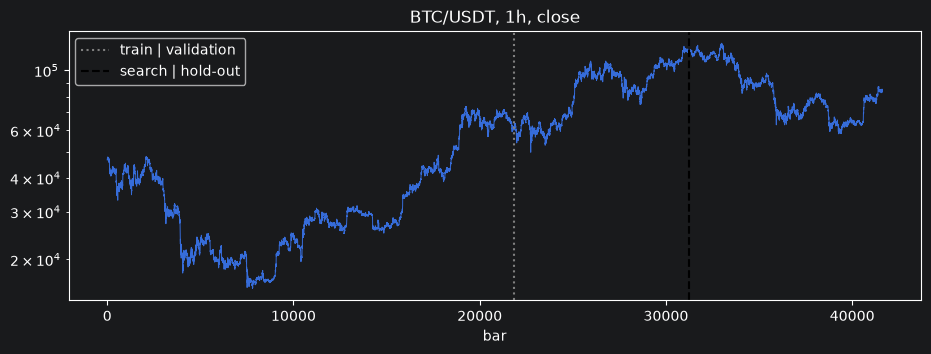

In [38]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(data["close"], lw=0.7)
ax.axvline(N_TRAIN, color="grey", ls=":", label="train | validation")
ax.axvline(N_SEARCH, color="black", ls="--", label="search | hold-out")
ax.set_yscale("log")
ax.set_title(f"{SYMBOL}, {TIMEFRAME}, close")
ax.set_xlabel("bar")
ax.legend()
plt.show()

## 0: Random ##


In [39]:
runs = {}
# 0: Random
for seed in SEEDS:
    started = time.perf_counter()
    ledger = arm0_random.random_search(data, BUDGET, seed=seed, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("0: random", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 0, seed {seed}: {ledger.used} backtests, {minutes:.1f} min")

arm 0, seed 0: 2000 backtests, 0.1 min


## 5: GP + Optuna ##

In [ ]:
# 1: LLM generates the strategy and tunes parameters
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("1: LLM only", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 1, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

In [ ]:
# 2: GP creates strategy, LLM tunes parameters
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("2: GP + LLM", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 1, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

In [ ]:
# 3: LLM creates strategy, Optuna tunes parameters of every strategy
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("2: GP + LLM", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 1, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

In [ ]:
# 4: LLM creates strategy, Optuna tunes parameters of finalists
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("2: GP + LLM", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 1, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

In [41]:
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("5: GP + Optuna", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 5, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

arm 5, seed 0: 18 generations, 2000 backtests, 0.4 min


In [43]:
checks, curves = [], {}
for _, s in summary.iterrows():
    if not isinstance(s["rule"], str) or s["seed"] not in PLATFORM_SEEDS:
        continue
    result, seconds = pb.run_platform(s["rule"], make_provider, MONEY, **STRATEGY)
    result.buy_and_hold_curve = list(MONEY * data["close"] / data["close"][0])
    platform_curve = np.asarray(result.equity_curve, dtype=float) / MONEY
    free, _ = pb.fast_equity(data, s["rule"], 0.0)
    paid, _ = pb.fast_equity(data, s["rule"], COST_BPS)
    checks.append({
        "arm": s["arm"], "seed": s["seed"], "platform, s": round(seconds),
        **pb.prefixed("platform hold-out", pb.window_metrics(platform_curve, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, no costs", pb.window_metrics(free, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, costs", pb.window_metrics(paid, N_SEARCH, lab.BARS_PER_YEAR)),
        "engine: profit %": result.overall_profit_percent,
        "engine: max DD %": result.max_drawdown_percent,
        "engine: win rate %": result.win_rate_percent,
        "engine: sharpe (sqrt 252)": result.sharpe_ratio
    })
    curves[(s["arm"], s["seed"])] = platform_curve

buy_and_hold = data["close"] / data["close"][0]
checks.append({"arm": "buy & hold",
               **pb.prefixed("platform hold-out", pb.window_metrics(buy_and_hold, N_SEARCH, lab.BARS_PER_YEAR))})
pd.DataFrame(checks)

,arm,seed,"platform, s",platform hold-out: return %,platform hold-out: sharpe,platform hold-out: max DD %,"fast hold-out, no costs: return %","fast hold-out, no costs: sharpe","fast hold-out, no costs: max DD %","fast hold-out, costs: return %","fast hold-out, costs: sharpe","fast hold-out, costs: max DD %",engine: profit %,engine: max DD %,engine: win rate %,engine: sharpe (sqrt 252)
0,0: random,0.0,27.0,-45.005508,-1.783085,49.584471,-45.005508,-1.783085,49.584471,-46.375891,-1.863040,50.544532,59.145978,53.790830,25.000000,0.0793
1,5: GP + Optuna,0.0,7.0,-25.711240,-0.839275,47.341089,-25.711240,-0.839275,47.341089,-29.186271,-0.996896,47.968211,43.115984,47.341089,32.786885,0.0849
2,buy & hold,NaN,NaN,-29.491062,-0.490464,53.742065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
